In [4]:

import random
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# 1. Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 2. Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

# 3. Load Fashion-MNIST
transform = transforms.ToTensor()

full_train = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

# 4. Split training data
train_dataset, val_dataset = random_split(
    full_train,
    [54000, 6000],
    generator=torch.Generator().manual_seed(SEED)
)

# 5. Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

# 6. Class names
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress",
    "Coat", "Sandal", "Shirt", "Sneaker",
    "Bag", "Ankle boot"
]

print("\nDataset successfully loaded!")
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))


PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
Device: cpu


100%|██████████| 26.4M/26.4M [00:01<00:00, 22.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 346kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.33MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.8MB/s]



Dataset successfully loaded!
Training images: 54000
Validation images: 6000
Testing images: 10000


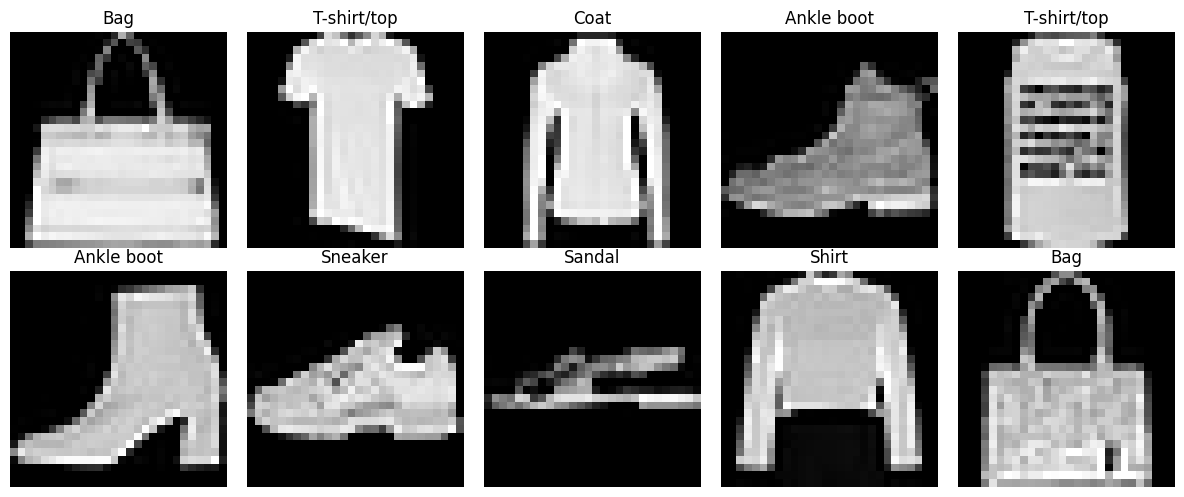

In [5]:

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [6]:

import torch
import torch.nn as nn
import torch.optim as optim
import time

# Reproducibility
torch.manual_seed(42)

# 1. Define Logistic Regression
class LogisticRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(28 * 28, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.linear(x)

# 2. Initialize model
model = LogisticRegressionModel().to(device)

# 3. Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 4. Evaluation function
def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    total_loss = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100 * correct / total

# 5. Train the model
epochs = 5
start_time = time.time()

for epoch in range(epochs):
    model.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

    train_loss = running_loss / len(train_loader.dataset)
    val_loss, val_accuracy = evaluate(model, val_loader)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Validation Loss: {val_loss:.4f} "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

training_time = time.time() - start_time

# 6. Count model parameters
parameters = sum(p.numel() for p in model.parameters())

print("\nTraining completed!")
print(f"Training time: {training_time:.2f} seconds")
print(f"Model parameters: {parameters:,}")

Epoch [1/5] Train Loss: 0.7464 Validation Loss: 0.5661 Validation Accuracy: 81.33%
Epoch [2/5] Train Loss: 0.5198 Validation Loss: 0.5070 Validation Accuracy: 83.25%
Epoch [3/5] Train Loss: 0.4754 Validation Loss: 0.4863 Validation Accuracy: 83.45%
Epoch [4/5] Train Loss: 0.4533 Validation Loss: 0.4643 Validation Accuracy: 84.47%
Epoch [5/5] Train Loss: 0.4388 Validation Loss: 0.4608 Validation Accuracy: 84.57%

Training completed!
Training time: 38.82 seconds
Model parameters: 7,850


In [7]:

# Experiment 2: Multi-Layer Perceptron

class MLPModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


# Initialize MLP
torch.manual_seed(42)

mlp_model = MLPModel().to(device)

criterion = nn.CrossEntropyLoss()
mlp_optimizer = optim.Adam(
    mlp_model.parameters(),
    lr=0.001
)

# Train MLP
epochs = 5
start_time = time.time()

for epoch in range(epochs):
    mlp_model.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        mlp_optimizer.zero_grad()

        outputs = mlp_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        mlp_optimizer.step()

        running_loss += loss.item() * labels.size(0)

    train_loss = running_loss / len(train_loader.dataset)

    val_loss, val_accuracy = evaluate(
        mlp_model, val_loader
    )

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Validation Loss: {val_loss:.4f} "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

mlp_training_time = time.time() - start_time

mlp_parameters = sum(
    p.numel() for p in mlp_model.parameters()
)

print("\nMLP training completed!")
print(f"Training time: {mlp_training_time:.2f} seconds")
print(f"Model parameters: {mlp_parameters:,}")


Epoch [1/5] Train Loss: 0.6056 Validation Loss: 0.4319 Validation Accuracy: 84.78%
Epoch [2/5] Train Loss: 0.4059 Validation Loss: 0.3861 Validation Accuracy: 86.17%
Epoch [3/5] Train Loss: 0.3685 Validation Loss: 0.3828 Validation Accuracy: 86.17%
Epoch [4/5] Train Loss: 0.3435 Validation Loss: 0.3562 Validation Accuracy: 87.20%
Epoch [5/5] Train Loss: 0.3269 Validation Loss: 0.3217 Validation Accuracy: 88.20%

MLP training completed!
Training time: 52.38 seconds
Model parameters: 235,146


In [8]:

# Experiment 3: Convolutional Neural Network

class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # First convolution block
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second convolution block
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# Initialize CNN
torch.manual_seed(42)

cnn_model = CNNModel().to(device)

criterion = nn.CrossEntropyLoss()

cnn_optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

# Train CNN
epochs = 5
start_time = time.time()

for epoch in range(epochs):
    cnn_model.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        cnn_optimizer.zero_grad()

        outputs = cnn_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        cnn_optimizer.step()

        running_loss += loss.item() * labels.size(0)

    train_loss = running_loss / len(train_loader.dataset)

    val_loss, val_accuracy = evaluate(
        cnn_model, val_loader
    )

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Validation Loss: {val_loss:.4f} "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

cnn_training_time = time.time() - start_time

cnn_parameters = sum(
    p.numel() for p in cnn_model.parameters()
)

print("\nCNN training completed!")
print(f"Training time: {cnn_training_time:.2f} seconds")
print(f"Model parameters: {cnn_parameters:,}")

Epoch [1/5] Train Loss: 0.7243 Validation Loss: 0.4591 Validation Accuracy: 83.43%
Epoch [2/5] Train Loss: 0.4448 Validation Loss: 0.3734 Validation Accuracy: 86.38%
Epoch [3/5] Train Loss: 0.3847 Validation Loss: 0.3449 Validation Accuracy: 87.53%
Epoch [4/5] Train Loss: 0.3547 Validation Loss: 0.3174 Validation Accuracy: 88.28%
Epoch [5/5] Train Loss: 0.3312 Validation Loss: 0.2995 Validation Accuracy: 88.80%

CNN training completed!
Training time: 186.83 seconds
Model parameters: 105,866


In [9]:

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

def get_predictions(model, loader):
    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )
            all_labels.extend(labels.numpy())

    return all_labels, all_predictions


trained_models = {
    "Logistic Regression": model,
    "MLP": mlp_model,
    "CNN": cnn_model
}

test_results = {}

for name, trained_model in trained_models.items():

    y_true, y_pred = get_predictions(
        trained_model, test_loader
    )

    accuracy = accuracy_score(y_true, y_pred)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    test_results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print(f"Test Accuracy: {accuracy * 100:.2f}%")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall: {recall:.4f}")
    print(f"Macro F1-score: {f1:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            y_pred,
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )


Logistic Regression
Test Accuracy: 83.55%
Macro Precision: 0.8340
Macro Recall: 0.8355
Macro F1-score: 0.8314

Classification Report:
              precision    recall  f1-score   support

 T-shirt/top     0.8176    0.8070    0.8123      1000
     Trouser     0.9675    0.9530    0.9602      1000
    Pullover     0.6910    0.7560    0.7221      1000
       Dress     0.8078    0.8740    0.8396      1000
        Coat     0.6854    0.7820    0.7305      1000
      Sandal     0.9443    0.8980    0.9206      1000
       Shirt     0.6892    0.4480    0.5430      1000
     Sneaker     0.9011    0.9290    0.9148      1000
         Bag     0.9110    0.9620    0.9358      1000
  Ankle boot     0.9247    0.9460    0.9352      1000

    accuracy                         0.8355     10000
   macro avg     0.8340    0.8355    0.8314     10000
weighted avg     0.8340    0.8355    0.8314     10000


MLP
Test Accuracy: 87.87%
Macro Precision: 0.8784
Macro Recall: 0.8787
Macro F1-score: 0.8775

Classifica

In [10]:

# Experiment 4: Robustness against Gaussian noise

import numpy as np
from sklearn.metrics import accuracy_score, f1_score

def evaluate_with_noise(model, loader, noise_std, seed=42):

    model.eval()

    all_predictions = []
    all_labels = []

    # Reproduce the same noise for every model
    torch.manual_seed(seed)

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            # Add Gaussian noise
            noise = torch.randn_like(images) * noise_std

            noisy_images = torch.clamp(
                images + noise,
                0.0,
                1.0
            )

            outputs = model(noisy_images)
            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return accuracy * 100, macro_f1


# Noise levels
noise_levels = [0.0, 0.1, 0.2, 0.3, 0.4]

trained_models = {
    "Logistic Regression": model,
    "MLP": mlp_model,
    "CNN": cnn_model
}

robustness_results = {}

for model_name, trained_model in trained_models.items():

    print("\n" + "=" * 55)
    print("MODEL:", model_name)
    print("=" * 55)

    robustness_results[model_name] = {}

    for noise in noise_levels:

        accuracy, f1 = evaluate_with_noise(
            trained_model,
            test_loader,
            noise,
            seed=42 + int(noise * 100)
        )

        robustness_results[model_name][noise] = {
            "accuracy": accuracy,
            "f1": f1
        }

        print(
            f"Noise: {noise:.1f} | "
            f"Accuracy: {accuracy:.2f}% | "
            f"Macro F1: {f1:.4f}"
        )

print("\nRobustness experiment completed!")


MODEL: Logistic Regression
Noise: 0.0 | Accuracy: 83.55% | Macro F1: 0.8314
Noise: 0.1 | Accuracy: 82.56% | Macro F1: 0.8227
Noise: 0.2 | Accuracy: 75.16% | Macro F1: 0.7460
Noise: 0.3 | Accuracy: 60.52% | Macro F1: 0.5964
Noise: 0.4 | Accuracy: 46.15% | Macro F1: 0.4462

MODEL: MLP
Noise: 0.0 | Accuracy: 87.87% | Macro F1: 0.8775
Noise: 0.1 | Accuracy: 85.40% | Macro F1: 0.8526
Noise: 0.2 | Accuracy: 74.73% | Macro F1: 0.7524
Noise: 0.3 | Accuracy: 55.71% | Macro F1: 0.5709
Noise: 0.4 | Accuracy: 40.48% | Macro F1: 0.4117

MODEL: CNN
Noise: 0.0 | Accuracy: 88.56% | Macro F1: 0.8843
Noise: 0.1 | Accuracy: 85.38% | Macro F1: 0.8544
Noise: 0.2 | Accuracy: 66.55% | Macro F1: 0.6730
Noise: 0.3 | Accuracy: 42.18% | Macro F1: 0.4152
Noise: 0.4 | Accuracy: 26.08% | Macro F1: 0.2158

Robustness experiment completed!


ROBUSTNESS RESULTS


Model,CNN,Logistic Regression,MLP
Noise Level,,,
0.0,88.56,83.55,87.87
0.1,85.38,82.56,85.40
0.2,66.55,75.16,74.73
0.3,42.18,60.52,55.71
0.4,26.08,46.15,40.48


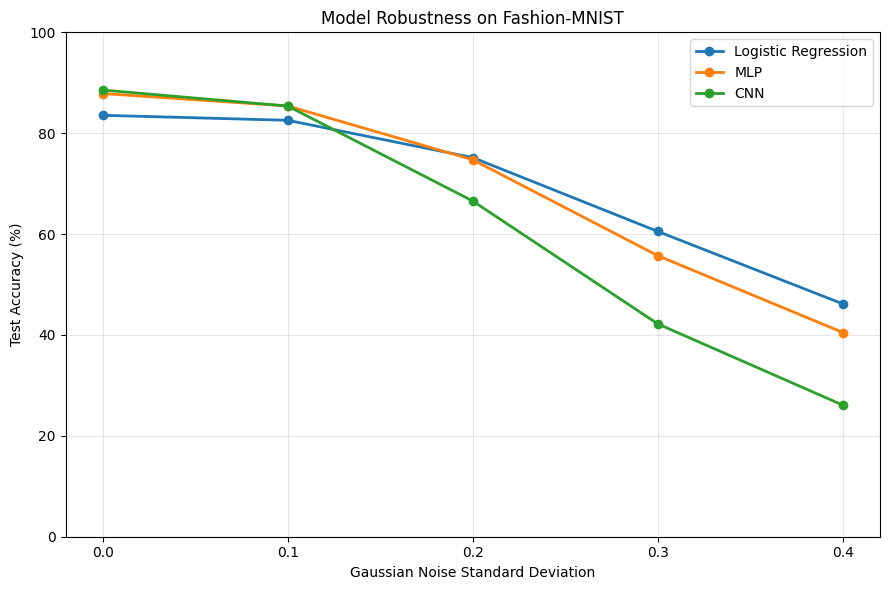

Saved robustness_results.csv
Saved robustness_accuracy.png


In [11]:

import pandas as pd
import matplotlib.pyplot as plt

# Convert robustness results into a table
records = []

for model_name, noise_data in robustness_results.items():
    for noise, metrics in noise_data.items():
        records.append({
            "Model": model_name,
            "Noise Level": noise,
            "Accuracy (%)": metrics["accuracy"],
            "Macro F1": metrics["f1"]
        })

robustness_df = pd.DataFrame(records)

# Display results
print("ROBUSTNESS RESULTS")
display(
    robustness_df.pivot(
        index="Noise Level",
        columns="Model",
        values="Accuracy (%)"
    ).round(2)
)

# Save experimental data
robustness_df.to_csv(
    "robustness_results.csv",
    index=False
)

# Plot accuracy vs noise
plt.figure(figsize=(9, 6))

for model_name in robustness_df["Model"].unique():
    subset = robustness_df[
        robustness_df["Model"] == model_name
    ]

    plt.plot(
        subset["Noise Level"],
        subset["Accuracy (%)"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.xlabel("Gaussian Noise Standard Deviation")
plt.ylabel("Test Accuracy (%)")
plt.title("Model Robustness on Fashion-MNIST")
plt.xticks([0, 0.1, 0.2, 0.3, 0.4])
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "robustness_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved robustness_results.csv")
print("Saved robustness_accuracy.png")

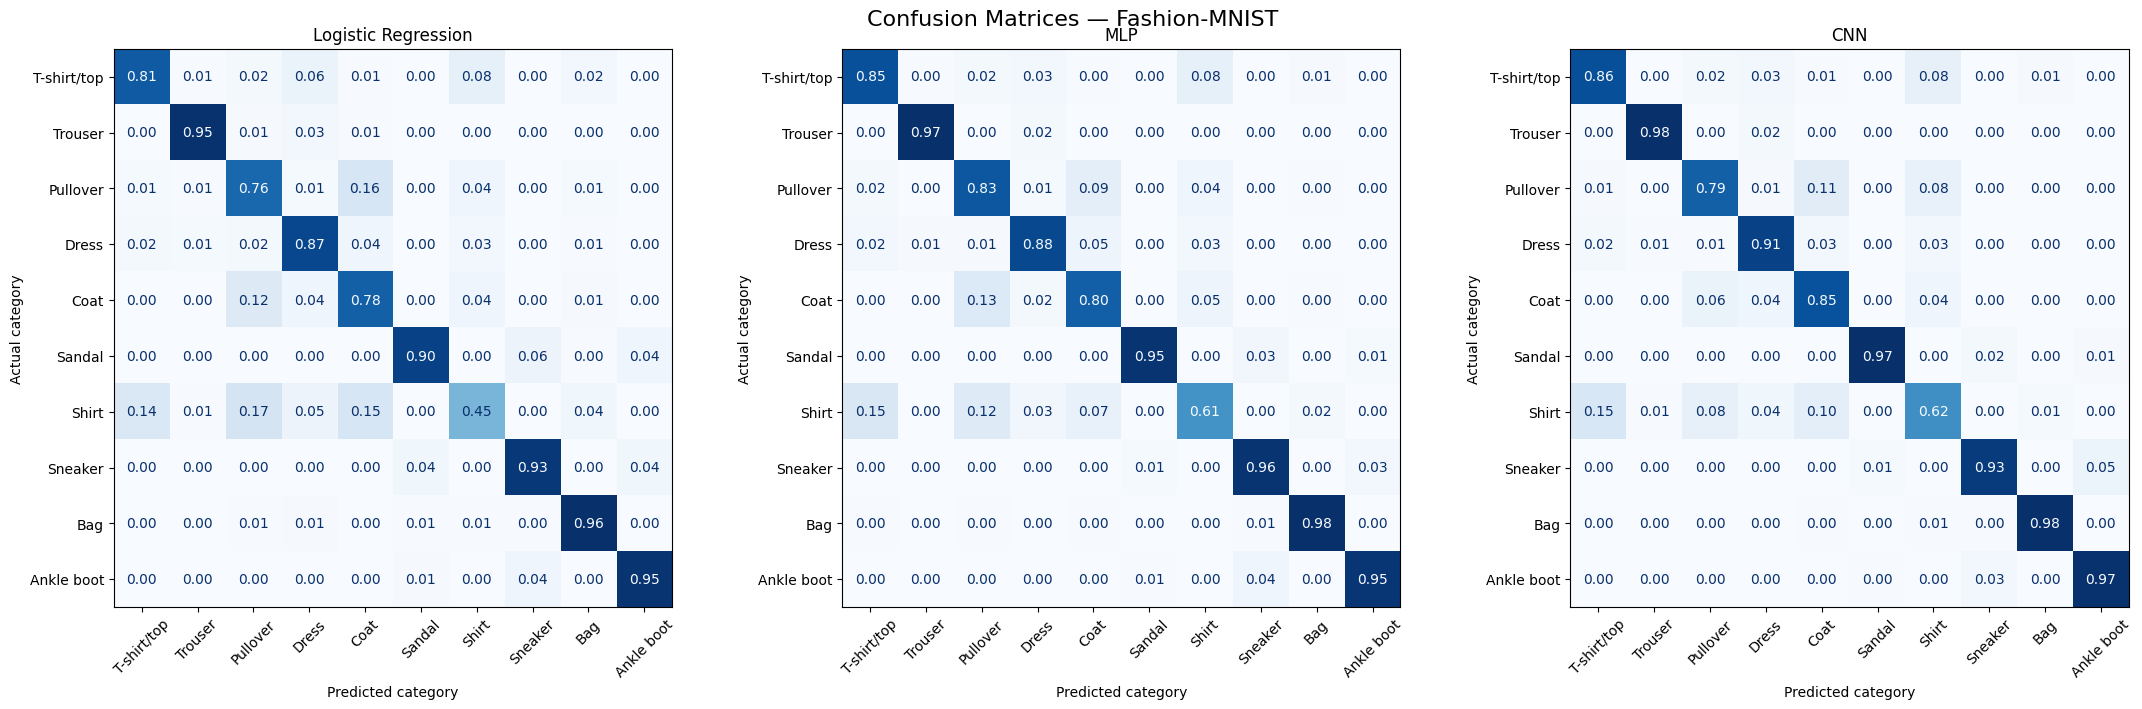

Saved confusion_matrices.png


In [14]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(22, 7))

for ax, (name, trained_model) in zip(
    axes, trained_models.items()
):

    # Get predictions on clean test images
    y_true, y_pred = get_predictions(
        trained_model, test_loader
    )

    # Normalize each row to show class-wise proportions
    cm = confusion_matrix(
        y_true,
        y_pred,
        normalize="true"
    )

    cm_display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    cm_display.plot(
        ax=ax,
        cmap="Blues",
        values_format=".2f",
        colorbar=False,
        xticks_rotation=45
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted category")
    ax.set_ylabel("Actual category")

plt.suptitle(
    "Confusion Matrices — Fashion-MNIST",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved confusion_matrices.png")

Model,CNN,Logistic Regression,MLP
Category,,,
Ankle boot,96.7,94.6,95.3
Bag,97.6,96.2,97.6
Coat,85.1,78.2,79.7
Dress,90.9,87.4,88.3
Pullover,79.3,75.6,82.9
Sandal,97.2,89.8,95.5
Shirt,62.0,44.8,60.6
Sneaker,93.4,92.9,95.9
T-shirt/top,85.8,80.7,85.4


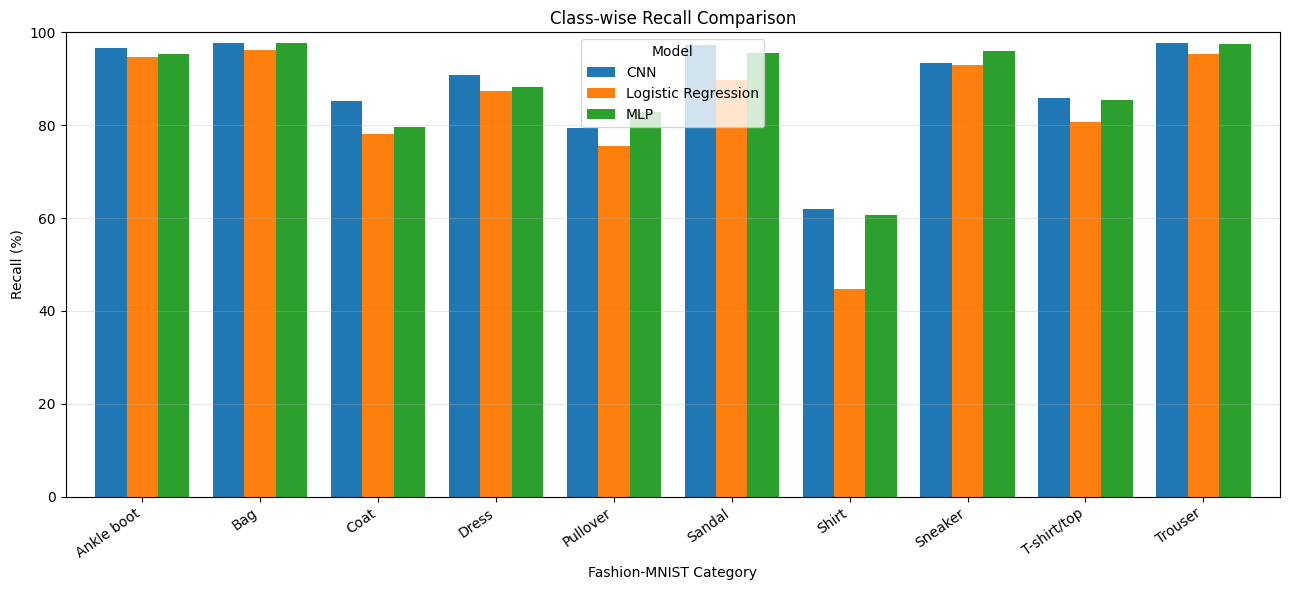

Saved class_wise_recall.csv
Saved class_wise_recall.png


In [15]:

from sklearn.metrics import recall_score
from IPython.display import display as show_table
import pandas as pd
import matplotlib.pyplot as plt

class_recall_records = []

for name, trained_model in trained_models.items():

    y_true, y_pred = get_predictions(
        trained_model, test_loader
    )

    recalls = recall_score(
        y_true,
        y_pred,
        average=None
    )

    for category, recall in zip(class_names, recalls):
        class_recall_records.append({
            "Model": name,
            "Category": category,
            "Recall (%)": recall * 100
        })

recall_df = pd.DataFrame(class_recall_records)

# Create comparison table
recall_table = recall_df.pivot(
    index="Category",
    columns="Model",
    values="Recall (%)"
)

show_table(recall_table.round(2))

# Save results
recall_df.to_csv(
    "class_wise_recall.csv",
    index=False
)

# Plot comparison
ax = recall_table.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

ax.set_title("Class-wise Recall Comparison")
ax.set_xlabel("Fashion-MNIST Category")
ax.set_ylabel("Recall (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Model")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    "class_wise_recall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved class_wise_recall.csv")
print("Saved class_wise_recall.png")


In [16]:

from torch.utils.data import DataLoader
import numpy as np
import pandas as pd
import time

seeds = [42, 123, 2026]

model_classes = {
    "Logistic Regression": LogisticRegressionModel,
    "MLP": MLPModel,
    "CNN": CNNModel
}

seed_results = []

def train_one_seed(model_class, seed, epochs=5):

    # Reproducible model initialization and dropout
    torch.manual_seed(seed)

    # Same shuffled data order for each architecture
    generator = torch.Generator()
    generator.manual_seed(seed)

    seeded_loader = DataLoader(
        train_loader.dataset,
        batch_size=train_loader.batch_size,
        shuffle=True,
        generator=generator,
        num_workers=train_loader.num_workers
    )

    current_model = model_class().to(device)

    optimizer = optim.Adam(
        current_model.parameters(),
        lr=0.001
    )

    start = time.time()

    for epoch in range(epochs):

        current_model.train()

        for images, labels in seeded_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = current_model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

    elapsed = time.time() - start

    # Evaluate only on validation data
    val_loss, val_accuracy = evaluate(
        current_model,
        val_loader
    )

    return val_accuracy, elapsed


for model_name, model_class in model_classes.items():

    print("\n" + "=" * 50)
    print("MODEL:", model_name)
    print("=" * 50)

    for seed in seeds:

        accuracy, elapsed = train_one_seed(
            model_class,
            seed,
            epochs=5
        )

        seed_results.append({
            "Model": model_name,
            "Seed": seed,
            "Validation Accuracy": accuracy,
            "Training Time": elapsed
        })

        print(
            f"Seed {seed} | "
            f"Validation Accuracy: {accuracy:.2f}% | "
            f"Time: {elapsed:.2f}s"
        )


# Summarize repeated experiments
seed_df = pd.DataFrame(seed_results)

summary = seed_df.groupby("Model").agg(
    Mean_Accuracy=("Validation Accuracy", "mean"),
    Std_Accuracy=("Validation Accuracy", "std"),
    Mean_Training_Time=("Training Time", "mean")
).round(3)

print("\nFINAL REPRODUCIBILITY SUMMARY")
print(summary)
seed_df.to_csv(
    "multiple_seed_results.csv",
    index=False
)

summary.to_csv(
    "reproducibility_summary.csv"
)

print("\nSaved both reproducibility CSV files!")



MODEL: Logistic Regression
Seed 42 | Validation Accuracy: 84.50% | Time: 34.64s
Seed 123 | Validation Accuracy: 84.48% | Time: 34.17s
Seed 2026 | Validation Accuracy: 84.05% | Time: 34.11s

MODEL: MLP
Seed 42 | Validation Accuracy: 87.82% | Time: 46.74s
Seed 123 | Validation Accuracy: 88.17% | Time: 47.36s
Seed 2026 | Validation Accuracy: 87.78% | Time: 47.40s

MODEL: CNN
Seed 42 | Validation Accuracy: 88.92% | Time: 166.59s
Seed 123 | Validation Accuracy: 89.40% | Time: 171.49s
Seed 2026 | Validation Accuracy: 88.68% | Time: 169.75s

FINAL REPRODUCIBILITY SUMMARY
                     Mean_Accuracy  Std_Accuracy  Mean_Training_Time
Model                                                               
CNN                         89.000         0.366             169.278
Logistic Regression         84.344         0.255              34.305
MLP                         87.922         0.212              47.169

Saved both reproducibility CSV files!
